# Observations and output sites

Define the onshore wave observations available for your case (buoys, tide gauges, spectral sites, ...), preview them on a map, and save a **JSON (GeoJSON format)** file compatible with QGIS and the HyGloW config loader.

Workflow:

1. Set the output file name/path in the parameters cell.
2. Build the buoys from the observation archive (`utils/buoy_archive.py`):
   stations of `inputs/Observations/raw/paulina/paulina.csv` (Waterinfo +
   CMEMS delivery, same folder) and the earlier Rijkswaterstaat exports,
   only those **inside the AoI**; stations within 1 km of each other are **one
   buoy**, merging all its sources into one hourly file
   (`inputs/Observations/processed/<instrument_id>.nc`: `hs`, `tp`, `dir`, `spr`).
3. Run the preview cells to check table and map.
4. Save the JSON to disk.
5. Add/update `"onshore_waves"` in the case JSON with the saved file path.
6. Build the output sites on the model mesh (isobaths + buoys) and check
   their mesh depths: the metamodel and dynamic runs use this table.

In [1]:
import os
import sys

# Must run before any GDAL-touching import (geopandas/pyogrio, rasterio/rioxarray).
# When the kernel is launched without going through `conda activate` (e.g. VS
# Code's Jupyter extension), GDAL_DATA/PROJ_DATA are unset, and importing
# rioxarray/rasterio before geopandas.read_file() in that state leaves GDAL's
# data-path auto-discovery broken for pyogrio, raising:
#   ValueError: Found GDAL data directory at .../share/gdal but it does not
#   appear to correctly contain GDAL data files
# Setting these explicitly sidesteps the broken auto-discovery.
os.environ.setdefault("GDAL_DATA", os.path.join(sys.prefix, "share", "gdal"))
os.environ.setdefault("PROJ_DATA", os.path.join(sys.prefix, "share", "proj"))

from utils import onshore_sites as obs
from utils import viz as plot
from utils.config import PATHS, resolve

## Parameters

In [2]:
from utils.config import ONSHORE_WAVES

# Output file — defaults to the path declared in the case config ("onshore_waves").
output_observations_file = ONSHORE_WAVES
output_path = resolve(output_observations_file)

print(f"output   : {output_path}")
print(f"AoI      : {resolve(PATHS['aoi_file'])}")
print(f"topobathy: {resolve(PATHS['topobathy_file'])}")

output   : /lustre/geocean/WORK/users/javiert/projects/HyGloW/Netherlands/inputs/Observations/Netherlands_observations.json
AoI      : /lustre/geocean/WORK/users/javiert/projects/HyGloW/Netherlands/inputs/AoI_Polygons/Netherlands_AoI.shp
topobathy: /lustre/geocean/WORK/users/javiert/projects/HyGloW/Netherlands/inputs/GRID/UGdcsm-fm_100m2coast3d_v3_era5bnd_net.tiff


## Observations from the buoy archive

Per buoy and variable, every matching source (Waterinfo folders and CMEMS
platforms within 1 km, earlier Rijkswaterstaat exports) is resampled to hourly
means (directions as vector means) and merged **longest record first**, the
others only filling its gaps. Waterinfo: Hm0 30-500 mHz, `tp = 1/fp`, mean
spectral direction and spreading, quality code `00`; CMEMS: `VHM0`, `VTPK`,
`VMDR`, `VPSP` with `value_qc == 1`. Ids of the earlier buoys are kept.

`build_buoys` writes each processed file once (slow the first time: it extracts
the Waterinfo files it needs); pass `overwrite=True` to rebuild. Buoys with less
than `min_hours` of hourly `hs` are left out of the observations; the ones
outside the model mesh (or too shallow) are dropped from the output sites at
the end of this notebook. Each buoy keeps its `measured_depth` (station
metadata).

In [3]:
from utils import buoy_archive as ba

stations = ba.catalog()
print(f"{len(stations)} stations, {int(stations.inside_aoi.sum())} inside the AoI")

# one buoy per group of stations within 1 km
stations = ba.group_stations(stations[stations.inside_aoi], max_distance_m=1000.0)
buoys = ba.build_buoys(stations)

observations = ba.observations_dict(buoys, min_hours=24 * 30)
print(f"{len(observations)} buoys kept of {len(buoys)}")
buoys.drop(columns="sources")

118 stations, 52 inside the AoI


INFO:hywaves.buoy_archive:A2: {'n_hs': 28851, 'n_tp': 0, 'n_dir': 0, 'n_spr': 0}
INFO:hywaves.buoy_archive:AWG: {'n_hs': 61585, 'n_tp': 57104, 'n_dir': 0, 'n_spr': 0}
INFO:hywaves.buoy_archive:Akkaert: {'n_hs': 39593, 'n_tp': 0, 'n_dir': 0, 'n_spr': 0}
INFO:hywaves.buoy_archive:Amelander31: {'n_hs': 82145, 'n_tp': 81412, 'n_dir': 20495, 'n_spr': 0}
INFO:hywaves.buoy_archive:AmelanderZeegat_1_1: {'n_hs': 85207, 'n_tp': 84111, 'n_dir': 84357, 'n_spr': 0}
INFO:hywaves.buoy_archive:BolVanHeistBuoy: {'n_hs': 44685, 'n_tp': 0, 'n_dir': 0, 'n_spr': 0}
INFO:hywaves.buoy_archive:Brouwershavensegat: {'n_hs': 202899, 'n_tp': 323824, 'n_dir': 0, 'n_spr': 0}
INFO:hywaves.buoy_archive:CadzandBoei: {'n_hs': 221470, 'n_tp': 221296, 'n_dir': 219342, 'n_spr': 219360}
INFO:hywaves.buoy_archive:Deurlo: {'n_hs': 72630, 'n_tp': 57220, 'n_dir': 72600, 'n_spr': 0}
INFO:hywaves.buoy_archive:DomburgerRassen: {'n_hs': 88845, 'n_tp': 252517, 'n_dir': 0, 'n_spr': 0}
INFO:hywaves.buoy_archive:EierlandseGat: {'n_hs'

44 buoys kept of 45


,instrument_id,lon,lat,depth,name,stations,start,end,n_hs,n_tp,n_dir,n_spr
0,A2,3.12000,51.36000,11.0,A2,A2,2020-02-28,2025-06-30,28851,0,0,0
1,AWG,5.95000,53.50000,11.0,AWG,AWG,2011-05-19,2025-06-30,61585,57104,0,0
2,Akkaert,2.82000,51.42000,22.0,Akkaert,Akkaert,2014-01-24,2025-06-30,39593,0,0,0
3,Amelander31,5.60000,53.45000,13.0,Amelander31,Amelander31,2003-12-10,2019-07-11,82145,81412,20495,0
4,AmelanderZeegat_1_1,5.48140,53.50760,18.0,"Amelander Zeegat, 1.1","Amelander11, AmelanderZeegat_1_1, AmelanderZee...",2003-12-04,2019-05-09,85207,84111,84357,0
5,BolVanHeistBuoy,3.20000,51.39000,13.0,BolVanHeistBuoy,BolVanHeistBuoy,2014-05-30,2025-06-30,44685,0,0,0
6,Brouwershavensegat,3.62000,51.77000,14.0,Brouwershavensegat,Brouwershavensegat,1998-07-20,2025-09-30,202899,323824,0,0
7,CadzandBoei,3.37000,51.39000,12.0,CadzandBoei,CadzandBoei,1997-11-24,2025-09-30,221470,221296,219342,219360
8,Deurlo,3.24000,51.50000,14.0,Deurlo,Deurlo,2011-05-19,2025-06-30,72630,57220,72600,0
9,DomburgerRassen,3.40000,51.62000,12.0,DomburgerRassen,DomburgerRassen,2014-05-29,2025-12-15,88845,252517,0,0


## Build GeoJSON and preview table

In [4]:
feature_collection = obs.dict_to_geojson(observations)
preview_df = obs.geojson_to_dataframe(feature_collection)
preview_df

,type,institution,recording,measured_depth,name,lon,lat
instrument_id,,,,,,,
A2,waves,Rijkswaterstaat / CMEMS,2020-02-28 to 2025-06-30,11.0,A2,3.12000,51.36000
AWG,waves,Rijkswaterstaat / CMEMS,2011-05-19 to 2025-06-30,11.0,AWG,5.95000,53.50000
Akkaert,waves,Rijkswaterstaat / CMEMS,2014-01-24 to 2025-06-30,22.0,Akkaert,2.82000,51.42000
Amelander31,waves,Rijkswaterstaat / CMEMS,2003-12-10 to 2019-07-11,13.0,Amelander31,5.60000,53.45000
AmelanderZeegat_1_1,waves,Rijkswaterstaat / CMEMS,2003-12-04 to 2019-05-09,18.0,"Amelander Zeegat, 1.1",5.48140,53.50760
BolVanHeistBuoy,waves,Rijkswaterstaat / CMEMS,2014-05-30 to 2025-06-30,13.0,BolVanHeistBuoy,3.20000,51.39000
Brouwershavensegat,waves,Rijkswaterstaat / CMEMS,1998-07-20 to 2025-09-30,14.0,Brouwershavensegat,3.62000,51.77000
CadzandBoei,waves,Rijkswaterstaat / CMEMS,1997-11-24 to 2025-09-30,12.0,CadzandBoei,3.37000,51.39000
Deurlo,waves,Rijkswaterstaat / CMEMS,2011-05-19 to 2025-06-30,14.0,Deurlo,3.24000,51.50000


## Map

Using Esri World Imagery (ArcGIS):
- Free for public and non-commercial use
- Commercial use allowed under Esri terms of service
- Attribution required: 'Tiles © Esri — Sources: Esri, Earthstar Geographics, CNES/Airbus DS, USDA, USGS, AeroGRID, IGN, and the GIS User Community'
- Max zoom ~19


(<Figure size 900x700 with 1 Axes>,
 <GeoAxes: title={'center': 'Netherlands — Case observations'}, xlabel='longitude', ylabel='latitude'>)

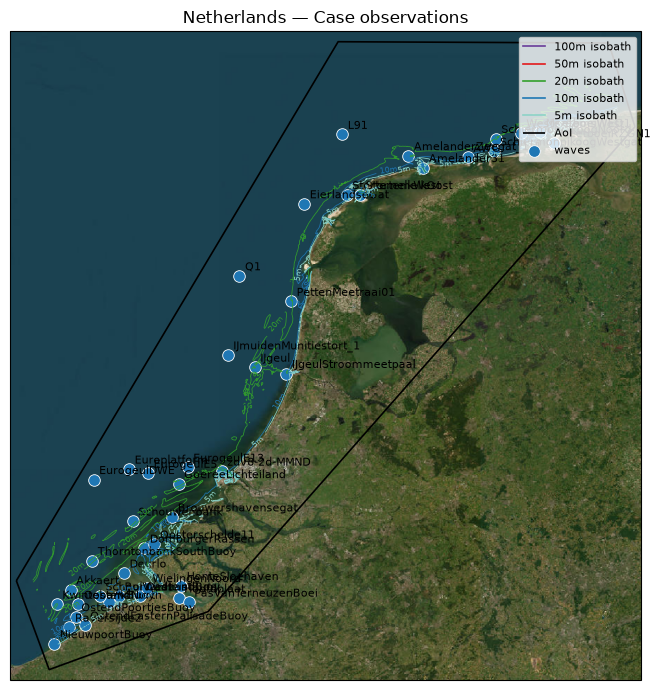

In [5]:
plot.plot_case_map(
    obs.dict_to_gdf(observations), title="Case observations", show_satellite=True
)

## Save observations JSON (GeoJSON format)

In [6]:
obs.save_geojson(feature_collection, output_path)

print(f"Wrote {len(feature_collection['features'])} feature(s) to:\n  {output_path}")

Wrote 44 feature(s) to:
  /lustre/geocean/WORK/users/javiert/projects/HyGloW/Netherlands/inputs/Observations/Netherlands_observations.json


## Update the case JSON

After saving, add or update this key in the case JSON so downstream notebooks use your new file:

```json
"onshore_waves": "inputs/Observations/<Case>_observations.json"
```

Use the exact relative path you set in `output_observations_file`.

## Output sites on the model mesh

All output sites are built here, once, on the mesh of `simulations.model`
(`simulations.<model>.grid_file`): isobaths traced on the topobathy raster
blanked outside the mesh (`simulations.output_sites_config`), plus the buoys
just saved. Each site gets its **`mesh_depth`** (the depth the models see, used
from here on) next to its nominal depth (contour level, or the buoy's
`measured_depth`), and is kept only if it is inside the mesh and still wet at
the lowest metamodel water level (`simulations.bounds.wl[0]`, with
`simulations.min_depth`).

The table, dropped sites included, goes to `outputs/output_sites_{model}.csv`;
the metamodel cases (05) and the dynamic runs (08) read it. Rebuilding it
(`recompute=True`) invalidates runs made with the old sites.

In [7]:
from utils.geometry import buoy_depth_check, output_sites, sites_summary

sites = output_sites(recompute=True, all_sites=True)
sites_summary(sites)

INFO:hywaves.geometry:Polygon DeenHaag: 1884 nodes, 1414 always wet -> 141 sites (fraction 0.1)
INFO:hywaves.geometry:Dropped 7/5163 sites (outside the mesh, or dry at wl -3.25 m with min depth 0.10 m): 5m can_dry 1; waves outside_mesh 6
INFO:hywaves.geometry:Output sites (snapwave): 5156 of 5163 ok -> /lustre/geocean/WORK/users/javiert/projects/HyGloW/Netherlands/outputs/output_sites_snapwave.csv


,sites,ok,outside_mesh,can_dry,min,p10,median,p90,max
group,,,,,,,,,
5m,1176.0,1175.0,0.0,1.0,3.5,4.9,5.0,5.1,6.2
10m,1875.0,1875.0,0.0,0.0,6.8,9.9,10.0,10.1,11.6
20m,1927.0,1927.0,0.0,0.0,15.4,19.8,20.0,20.2,21.7
DeenHaag,141.0,141.0,0.0,0.0,3.6,8.0,19.2,22.8,28.5
buoy,44.0,38.0,6.0,0.0,8.3,10.0,15.0,27.2,30.4
total,5163.0,5156.0,6.0,1.0,NaN,NaN,NaN,NaN,NaN


Buoys: measured depth (station metadata) against the mesh depth. A large
difference (`flag`) points to wrong coordinates, a bank or channel the mesh
smooths out, or another vertical datum.

In [8]:
buoy_depth_check(sites)

,source_id,name,measured_depth,mesh_depth,difference,status,flag
0,buoy_A2,A2,11.0,10.4,-0.6,ok,False
1,buoy_AWG,AWG,11.0,10.0,-1.0,ok,False
2,buoy_Akkaert,Akkaert,22.0,22.6,0.6,ok,False
3,buoy_Amelander31,Amelander31,13.0,15.0,2.0,ok,False
4,buoy_AmelanderZeegat_1_1,"Amelander Zeegat, 1.1",18.0,19.1,1.1,ok,False
5,buoy_BolVanHeistBuoy,BolVanHeistBuoy,13.0,12.2,-0.8,ok,False
6,buoy_Brouwershavensegat,Brouwershavensegat,14.0,11.0,-3.0,ok,False
7,buoy_CadzandBoei,CadzandBoei,12.0,10.5,-1.5,ok,False
8,buoy_Deurlo,Deurlo,14.0,10.0,-4.0,ok,False
9,buoy_DomburgerRassen,DomburgerRassen,12.0,12.7,0.7,ok,False


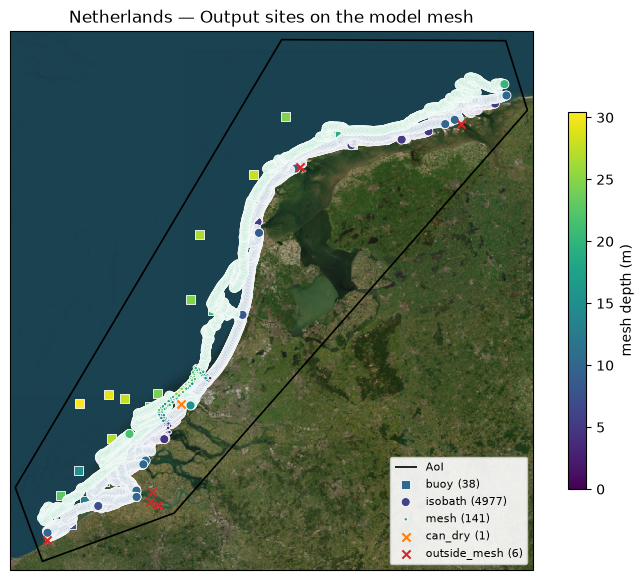

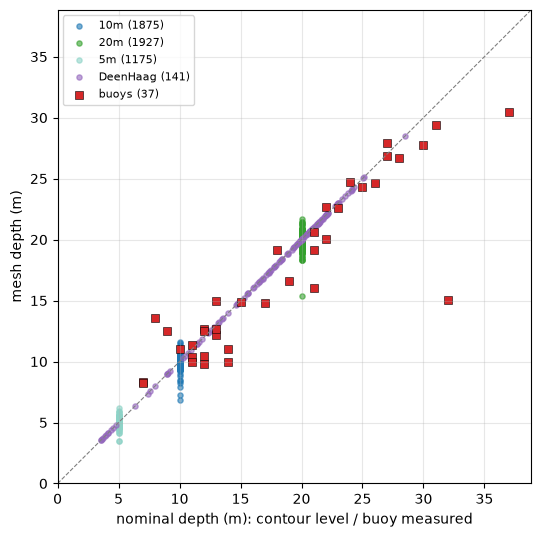

In [9]:
plot.plot_output_sites(sites, show_satellite=True)
plot.plot_site_depths(sites);